# Импорты библиотек.

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
from statsmodels.tsa.seasonal import STL

# Описание датасета.

В качестве датасета для был выбран открытый датасет Store Sales - Time Series Forecasting с платформы Kaggle. Набор данных содержит исторические данные о продажах сети супермаркетов.

Целевая переменная: Числовой показатель sales — суммарный объем продаж (в денежном выражении) по всей торговой сети за каждый день.

Временной диапазон: Исходные данные охватывают период с 1 января 2013 года по 15 августа 2017 года.

# Загрузка и визуализация.

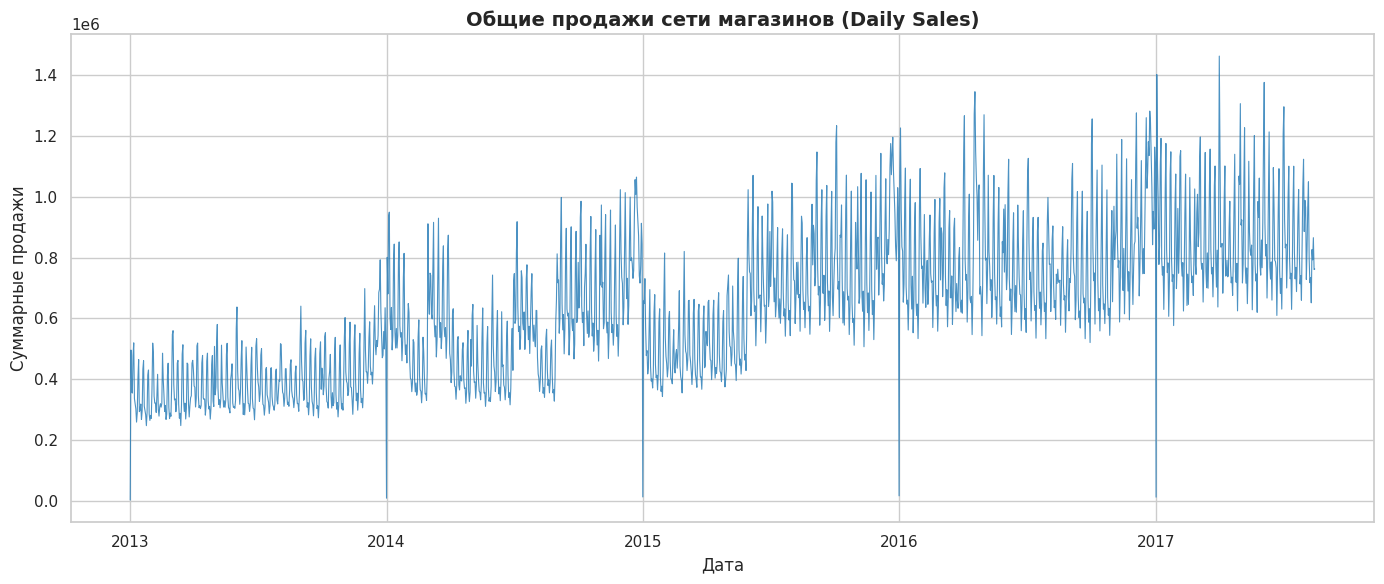

Начало периода: 2013-01-01 00:00:00
Конец периода: 2017-08-15 00:00:00
Всего дней в ряде: 1684


In [102]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)

train_df = pd.read_csv('train.csv')

train_df['date'] = pd.to_datetime(train_df['date'])
train_df = train_df.sort_values('date')

daily_sales = train_df.groupby('date')['sales'].sum().reset_index()
daily_sales.set_index('date', inplace=True)

plt.figure()
plt.plot(daily_sales.index, daily_sales['sales'], color='tab:blue', linewidth=0.8, alpha=0.8)
plt.title('Общие продажи сети магазинов (Daily Sales)', fontsize=14, fontweight='bold')
plt.ylabel('Суммарные продажи', fontsize=12)
plt.xlabel('Дата', fontsize=12)
plt.tight_layout()
plt.show()

print(f"Начало периода: {daily_sales.index.min()}")
print(f"Конец периода: {daily_sales.index.max()}")
print(f"Всего дней в ряде: {len(daily_sales)}")

На основе полученного графика можно сделать следующие выводы:
* Наблюдается тренд в объемах продаж. Среднее количество продаж увеличивается, так как минимальное и максимальное значение продаж за год вырастает.
* Присутствует сезонность. В конце года продажи растут, а в начале следующего года, или спустя некоторое время после начала нового года, продажи падают, но, потом снова поднимаются. Такую сезонность можно отнести к годовой (новогодний ажиотаж).
* Выбросы присутствуют. Есть значения, которые превышают значение среднего, возможно, из-за распродаж. Также есть дни, когда число продаж было равно 0, скорее всего, в выходные дни.

# Признаки.

In [103]:
df_features = daily_sales.copy()

df_features['year'] = df_features.index.year
df_features['month'] = df_features.index.month
df_features['day'] = df_features.index.day
df_features['dayofweek'] = df_features.index.dayofweek
df_features['is_weekend'] = df_features['dayofweek'].isin([5, 6]).astype(int)

for lag in [1, 2, 7, 14]:
    df_features[f'lag_{lag}'] = df_features['sales'].shift(lag)

window = 7
df_features[f'rolling_mean_{window}'] = df_features['sales'].shift(1).rolling(window=window).mean()
df_features[f'rolling_std_{window}'] = df_features['sales'].shift(1).rolling(window=window).std()
df_features[f'rolling_min_{window}'] = df_features['sales'].shift(1).rolling(window=window).min()
df_features[f'rolling_max_{window}'] = df_features['sales'].shift(1).rolling(window=window).max()

df_features['lag_365'] = df_features['sales'].shift(365)

df_features = df_features.dropna()

print(f"Размер датасета после генерации признаков и очистки NaN: {df_features.shape}")
print(df_features.head(3))

Размер датасета после генерации признаков и очистки NaN: (1319, 15)
                    sales  year  month  day  dayofweek  is_weekend  \
date                                                                 
2014-01-02  801011.226041  2014      1    2          3           0   
2014-01-03  680672.845603  2014      1    3          4           0   
2014-01-04  936628.886604  2014      1    4          5           1   

                    lag_1          lag_2          lag_7         lag_14  \
date                                                                     
2014-01-02    8602.065404  507264.663048  470731.162414  527481.336925   
2014-01-03  801011.226041    8602.065404  479314.968043  507461.038187   
2014-01-04  680672.845603  801011.226041  556952.305979  544104.267636   

            rolling_mean_7  rolling_std_7  rolling_min_7  rolling_max_7  \
date                                                                      
2014-01-02   451102.772237  203132.842143    8602.065404  63

Для перевода задачи прогнозирования временного ряда в формат классического машинного обучения была сформирована матрица признаков исключительно на основе прецедентов из прошлого (во избежание утечки данных). Были выделены следующие группы признаков:

Календарные признаки: год, месяц, день месяца, день недели и флаг выходного дня (is_weekend), позволяющие модели улавливать календарные циклы.

Лаги: значения целевой переменной с лагами в 1, 2, 7 и 14 дней для учета кратковременной и недельной инерции процессов.

Скользящие статистики: скользящее среднее, стандартное отклонение, минимум и максимум за 7-дневное окно (вычисленные со сдвигом shift(1)), отражающие локальный тренд.

Сезонный лаг: значение продаж ровно год назад (lag_365), необходимое для захвата годовой сезонности, явно выраженной на графике в виде декабрьских пиков.

# Разделение и кросс-валидация.

In [104]:
features = [col for col in df_features.columns if col != 'sales']

X = df_features[features]
y = df_features['sales']

df_features = df_features.sort_index()
X = df_features[features]
y = df_features['sales']

test_size = 180

X_train, X_test = X.iloc[:-test_size], X.iloc[-test_size:]
y_train, y_test = y.iloc[:-test_size], y.iloc[-test_size:]

print(f"Всего строк: {len(df_features)}")
print(f"Train: {len(X_train)} дней")
print(f"Test: {len(X_test)} дней")
print(f"Период Train: {X_train.index.min()} — {X_train.index.max()}")
print(f"Период Test:  {X_test.index.min()} — {X_test.index.max()}")

tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
}

grid_search = GridSearchCV(
    estimator=Ridge(),
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=tscv,
    refit=True,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_alpha = grid_search.best_params_['alpha']

print("\nРезультаты подбора:")
print(f"Лучший alpha: {best_alpha}")
print(f"Лучшая средняя MAE на кросс-валидации: "
      f"{-grid_search.best_score_:.2f}")

Всего строк: 1319
Train: 1139 дней
Test: 180 дней
Период Train: 2014-01-02 00:00:00 — 2017-02-16 00:00:00
Период Test:  2017-02-17 00:00:00 — 2017-08-15 00:00:00

Результаты подбора:
Лучший alpha: 100.0
Лучшая средняя MAE на кросс-валидации: 75253.29


По результатам кросс-валидации, можно сделать вывод, что лучшим aplha для данной модели будет 100, так как у модели с этим значением самое низкое MAE.

# Модель.

In [105]:
model = grid_search.best_estimator_

history_sales = list(y_train.values)
recursive_preds = []

for i, (idx, row) in enumerate(X_test.iterrows()):
    feat = row.copy()

    feat['lag_1'] = history_sales[-1]
    feat['lag_2'] = history_sales[-2]
    feat['lag_7'] = history_sales[-7]
    feat['lag_14'] = history_sales[-14]
    feat['lag_365'] = history_sales[-365]

    recent = history_sales[-7:]
    feat['rolling_mean_7'] = np.mean(recent)
    feat['rolling_std_7'] = pd.Series(recent).std(ddof=1)
    feat['rolling_min_7'] = np.min(recent)
    feat['rolling_max_7'] = np.max(recent)

    pred = model.predict(pd.DataFrame([feat])[X_train.columns])[0]
    recursive_preds.append(pred)

    history_sales.append(pred)

y_pred_test = pd.Series(recursive_preds, index=X_test.index)

Мы использовали Ridge-регрессию, так как она оптимально подходит для работы с признаками временных рядов (лаги и скользящие статистики), обладающими высокой корреляцией между собой. В отличие от обычной линейной регрессии, Ridge предотвращает переобучение за счет $L_2$-регуляризации, а в отличие от Lasso — не удаляет полезные признаки целиком, а плавно стабилизирует их веса

# Оценка качества.

In [106]:
def calculate_metrics(y_true, y_pred, name="Model"):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    wape = (np.sum(np.abs(y_true - y_pred)) / np.sum(y_true)) * 100

    print(f"--- Метрики качества ({name}) ---")
    print(f"MSE:  {mse:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"MAE:  {mae:,.2f}")
    print(f"MAPE: {mape:.2f}%")
    print(f"WAPE: {wape:.2f}%\n")
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'WAPE': wape}

y_pred_train = model.predict(X_train)

train_metrics = calculate_metrics(y_train, y_pred_train, name="Train")
test_metrics = calculate_metrics(y_test, y_pred_test, name="Test (Recursive)")

--- Метрики качества (Train) ---
MSE:  10,509,072,319.24
RMSE: 102,513.77
MAE:  65,526.12
MAPE: 26.97%
WAPE: 9.58%

--- Метрики качества (Test (Recursive)) ---
MSE:  31,298,496,290.82
RMSE: 176,913.81
MAE:  143,480.70
MAPE: 15.63%
WAPE: 16.71%



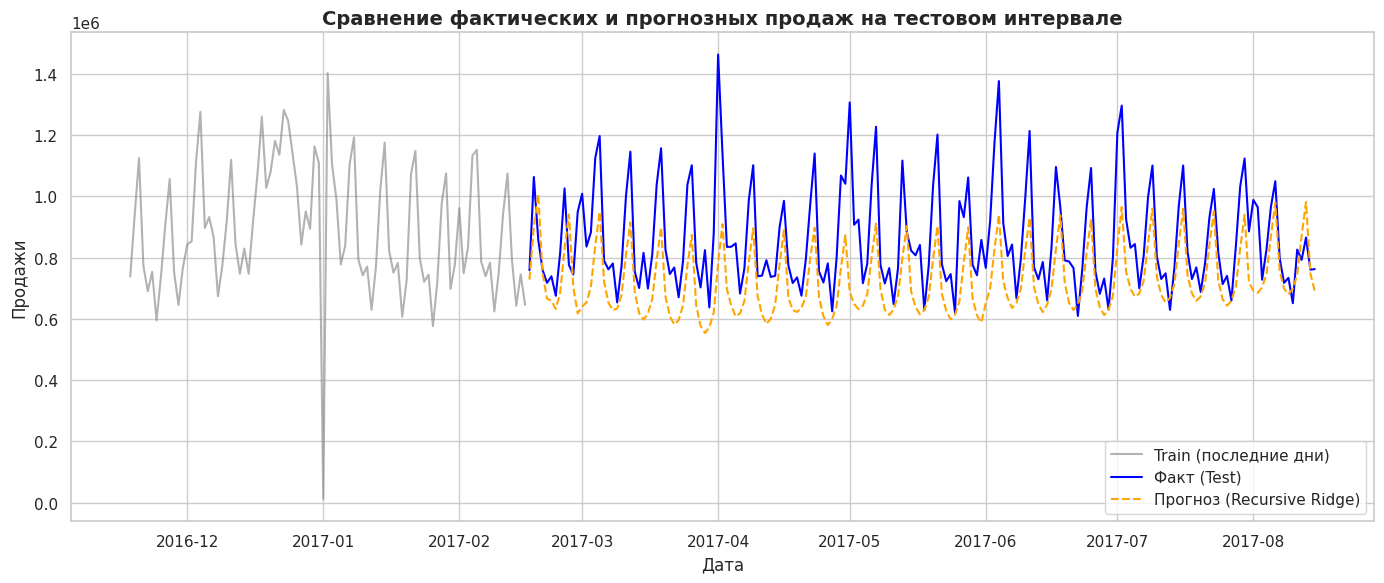

In [107]:
plt.figure(figsize=(14, 6))
plt.plot(y_train.index[-90:], y_train.values[-90:], label='Train (последние дни)', color='gray', alpha=0.6)
plt.plot(y_test.index, y_test.values, label='Факт (Test)', color='blue', linewidth=1.5)
plt.plot(y_test.index, y_pred_test.values, label='Прогноз (Recursive Ridge)', color='orange', linestyle='--', linewidth=1.5)
plt.title('Сравнение фактических и прогнозных продаж на тестовом интервале', fontsize=14, fontweight='bold')
plt.xlabel('Дата')
plt.ylabel('Продажи')
plt.legend()
plt.tight_layout()
plt.show()

Для оценки качества модели Ridge с рекурсивной стратегией прогнозирования были рассчитаны среднеквадратичная ошибка (MSE), средняя абсолютная ошибка (MAE), средняя абсолютная процентная ошибка (MAPE) и взвешенная абсолютная процентная ошибка (WAPE). Дополнительно рассчитана корень из среднеквадратичной ошибки (RMSE).

На обучающей выборке получены следующие значения: MSE — 10 509 072 319,24; MAE — 65 526,12; MAPE — 26,97%; WAPE — 9,58%. На тестовой выборке при рекурсивном прогнозировании MSE составила 31 298 496 290,82, MAE — 143 480,70, MAPE — 15,63%, WAPE — 16,71%.

Сравнение результатов показывает увеличение MAE примерно на 119%, RMSE — на 72,5%, а WAPE — на 7,13 процентного пункта. Рост абсолютных ошибок на тестовой выборке свидетельствует о снижении точности модели при прогнозировании будущих периодов. Одной из возможных причин является накопление ошибок при рекурсивном прогнозировании, когда ранее полученные предсказания используются для формирования признаков последующих шагов.

Визуальное сравнение фактических и прогнозных значений показывает, что модель воспроизводит часть регулярных колебаний продаж, но не всегда корректно оценивает амплитуду изменений. В частности, наблюдается недооценка отдельных пиков продаж и сглаживание резких колебаний. Такие отклонения особенно сильно влияют на MSE и RMSE.

При этом MAPE на тестовой выборке ниже, чем на обучающей. Это объясняется особенностями относительной метрики, чувствительной к малым фактическим значениям. Поэтому для оценки общей точности прогнозирования в данном случае целесообразно рассматривать MAPE совместно с MAE и WAPE.

Таким образом, модель Ridge выявляет определённые закономерности динамики продаж, однако её точность снижается при многошаговом рекурсивном прогнозировании.

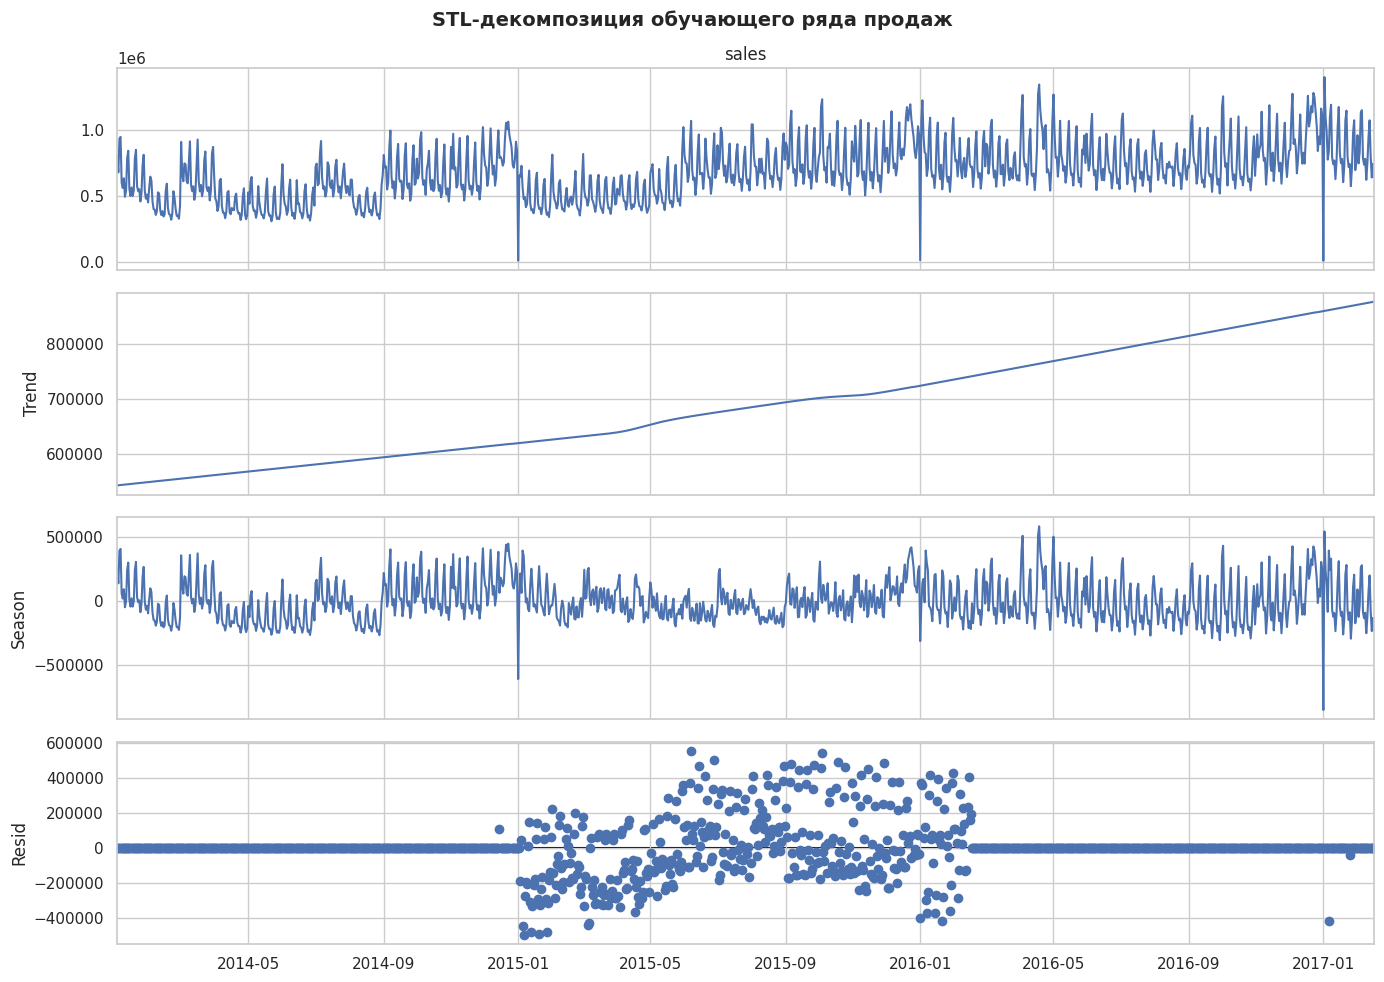

Лучший alpha STL-модели: 100.0
CV MAE STL-модели: 1907281.82659523

--- Base Ridge ---
MSE:  31,298,496,290.82
RMSE: 176,913.81
MAE:  143,480.70
MAPE: 15.63%
WAPE: 16.71%

--- Ridge with STL features ---
MSE:  21,781,791,215.99
RMSE: 147,586.55
MAE:  112,109.63
MAPE: 12.05%
WAPE: 13.06%

Сравнение моделей:
        Base Ridge  Ridge with STL
MSE   3.129850e+10    2.178179e+10
RMSE  1.769138e+05    1.475866e+05
MAE   1.434807e+05    1.121096e+05
MAPE  1.562821e+01    1.204844e+01
WAPE  1.671359e+01    1.305928e+01


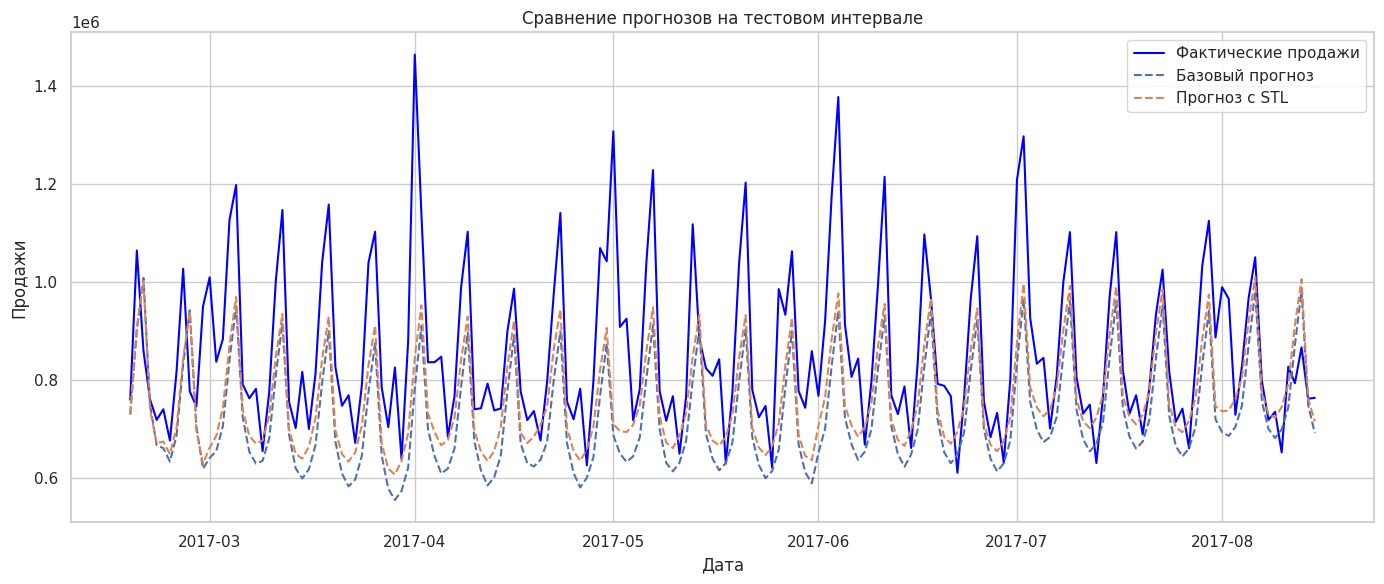

In [108]:
df_features = df_features.sort_index()

features = [col for col in df_features.columns if col != 'sales']
X = df_features[features]
y = df_features['sales']

test_size = 180

X_train = X.iloc[:-test_size].copy()
X_test = X.iloc[-test_size:].copy()
y_train = y.iloc[:-test_size].copy()
y_test = y.iloc[-test_size:].copy()

stl_train = STL(
    y_train,
    period=365,
    robust=True
).fit()

fig = stl_train.plot()
fig.set_size_inches(14, 10)
plt.suptitle(
    'STL-декомпозиция обучающего ряда продаж',
    fontsize=14,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

X_train_stl = X_train.copy()

X_train_stl['trend_lag_1'] = stl_train.trend.shift(1)
X_train_stl['seasonal_lag_1'] = stl_train.seasonal.shift(1)
X_train_stl['resid_lag_1'] = stl_train.resid.shift(1)

valid = X_train_stl.notna().all(axis=1)

X_train_stl = X_train_stl.loc[valid]
y_train_stl = y_train.loc[valid]

tscv_stl = TimeSeriesSplit(n_splits=5)

grid_stl = GridSearchCV(
    estimator=Ridge(),
    param_grid={
        'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
    },
    scoring='neg_mean_absolute_error',
    cv=tscv_stl,
    refit=True,
    n_jobs=-1
)

grid_stl.fit(X_train_stl, y_train_stl)

model_stl = grid_stl.best_estimator_

print('Лучший alpha STL-модели:',
      grid_stl.best_params_['alpha'])
print('CV MAE STL-модели:',
      -grid_stl.best_score_)

time_train = np.arange(len(stl_train.trend)).reshape(-1, 1)

trend_model = LinearRegression()
trend_model.fit(time_train, stl_train.trend.values)

seasonal_train = pd.DataFrame({
    'dayofyear': stl_train.seasonal.index.dayofyear,
    'seasonal': stl_train.seasonal.values
})

seasonal_profile = seasonal_train.groupby(
    'dayofyear'
)['seasonal'].mean()

history_sales = list(y_train.values)
trend_history = list(stl_train.trend.values)
seasonal_history = list(stl_train.seasonal.values)
resid_history = list(stl_train.resid.values)

recursive_preds_stl = []

for idx, row in X_test.iterrows():

    feat = row.copy()

    feat['lag_1'] = history_sales[-1]
    feat['lag_2'] = history_sales[-2]
    feat['lag_7'] = history_sales[-7]
    feat['lag_14'] = history_sales[-14]
    feat['lag_365'] = history_sales[-365]

    recent = history_sales[-7:]

    feat['rolling_mean_7'] = np.mean(recent)
    feat['rolling_std_7'] = pd.Series(recent).std(ddof=1)
    feat['rolling_min_7'] = np.min(recent)
    feat['rolling_max_7'] = np.max(recent)

    t = len(trend_history)
    trend_next = trend_model.predict(
        np.array([[t]])
    )[0]

    day_of_year = idx.dayofyear
    seasonal_next = seasonal_profile.get(
        day_of_year,
        seasonal_profile.mean()
    )

    resid_next = 0.0

    feat['trend_lag_1'] = trend_history[-1]
    feat['seasonal_lag_1'] = seasonal_history[-1]
    feat['resid_lag_1'] = resid_history[-1]

    X_next = pd.DataFrame(
        [feat],
        columns=X_train_stl.columns
    )

    pred = model_stl.predict(X_next)[0]

    recursive_preds_stl.append(pred)
    history_sales.append(pred)

    trend_history.append(trend_next)
    seasonal_history.append(seasonal_next)
    resid_history.append(resid_next)

y_pred_test_stl = pd.Series(
    recursive_preds_stl,
    index=X_test.index,
    name='Predicted_sales_STL'
)

def calculate_metrics(y_true, y_pred, name='Model'):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)

    mape = mean_absolute_percentage_error(
        y_true, y_pred
    ) * 100

    wape = (
        np.sum(np.abs(np.asarray(y_true) - np.asarray(y_pred)))
        / np.sum(np.abs(np.asarray(y_true)))
    ) * 100

    print(f'\n--- {name} ---')
    print(f'MSE:  {mse:,.2f}')
    print(f'RMSE: {rmse:,.2f}')
    print(f'MAE:  {mae:,.2f}')
    print(f'MAPE: {mape:.2f}%')
    print(f'WAPE: {wape:.2f}%')

    return {
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'MAPE': mape,
        'WAPE': wape
    }

metrics_base = calculate_metrics(
    y_test, y_pred_test, 'Base Ridge'
)

metrics_stl = calculate_metrics(
    y_test, y_pred_test_stl, 'Ridge with STL features'
)

comparison = pd.DataFrame({
    'Base Ridge': metrics_base,
    'Ridge with STL': metrics_stl
})

print('\nСравнение моделей:')
print(comparison)

plt.figure(figsize=(14, 6))
plt.plot(y_test.index, y_test.values,
         label='Фактические продажи', color='blue')
plt.plot(y_test.index, y_pred_test.values,
         label='Базовый прогноз', linestyle='--')
plt.plot(y_test.index, y_pred_test_stl.values,
         label='Прогноз с STL', linestyle='--')
plt.title('Сравнение прогнозов на тестовом интервале')
plt.xlabel('Дата')
plt.ylabel('Продажи')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Для исследования структуры временного ряда продаж была выполнена STL-декомпозиция с годовым сезонным периодом. Полученные компоненты позволяют выделить долгосрочную тенденцию, регулярные колебания и остаточные отклонения. На графике тренда наблюдается общий рост уровня продаж, а сезонная компонента отражает повторяющиеся колебания временного ряда.

Для проверки полезности компонент декомпозиции в прогнозировании была построена модель Ridge с дополнительными лаговыми признаками тренда, сезонности и остатка. Качество данной модели сравнивалось с качеством базовой модели Ridge на одном и том же тестовом интервале.

Результаты показали улучшение всех рассмотренных метрик. Средняя абсолютная ошибка MAE уменьшилась с 143 480,70 до 112 109,63, среднеквадратичная ошибка MSE — с 31 298 496 290,82 до 21 781 791 215,99. Значение MAPE снизилось с 15,63% до 12,05%, а WAPE — с 16,71% до 13,06%. Таким образом, в проведённом эксперименте модель с дополнительными STL-признаками продемонстрировала более высокую точность прогнозирования на тестовой выборке.

Таким образом, предварительные результаты свидетельствуют о потенциальной полезности STL-признаков для прогнозирования продаж.